# Shift Cipher: Implementation, Testing, and Cryptanalysis

## 1. Introduction

The Shift Cipher, commonly known as the Caesar Cipher, is a classical symmetric substitution cipher. It encrypts a message by replacing each letter with another letter a fixed number of positions away in the English alphabet.

The sender and receiver use the same secret key, which determines the number of positions by which letters are shifted.

This project implements the Shift Cipher from scratch in Python and explores its mathematical foundation, encryption and decryption procedures, input validation, automated testing, brute-force attacks, and security limitations.

### Project objectives

- Understand the mathematical principles behind substitution ciphers.
- Implement encryption and decryption using modular arithmetic.
- Handle uppercase letters, lowercase letters, spaces, punctuation, and numeric characters.
- Test the implementation against normal inputs and edge cases.
- Demonstrate brute-force cryptanalysis.
- Understand why classical shift ciphers are unsuitable for protecting sensitive information.

### Technologies used

- Python 3
- Python standard library
- Google Colab

No external cryptography libraries are required for the core implementation.

## 2. Mathematical Foundation

The Shift Cipher operates on the 26 letters of the English alphabet. To perform encryption mathematically, each letter is represented by an integer.

| Letter | Numerical value |
|---|---:|
| A | 0 |
| B | 1 |
| C | 2 |
| ... | ... |
| Z | 25 |

Let:

- \(P\) represent the numerical value of a plaintext letter.
- \(C\) represent the numerical value of its ciphertext equivalent.
- \(k\) represent the secret shift key.

### Encryption

The encryption formula is:

\[
C = (P+k)\bmod 26
\]

The key is added to the plaintext value, and the modulo operation ensures that the result remains within the range 0–25.

### Decryption

The decryption formula is:

\[
P = (C-k)\bmod 26
\]

Decryption reverses the shift applied during encryption.

### Example

Consider encrypting the letter X using a key of 3.

- X corresponds to 23.
- Adding the key gives \(23+3=26\).
- Applying modulo 26 gives \(26\bmod 26=0\).
- The numerical value 0 corresponds to A.

Therefore, X encrypts to A.

### Why modular arithmetic is necessary

Without the modulo operation, shifting letters near the end of the alphabet would produce values outside the valid alphabet range. Modulo arithmetic wraps these values around to the beginning of the alphabet.

A key of 26 produces no change because the alphabet contains 26 letters. Consequently, keys that differ by multiples of 26 are equivalent.

## 3. Encryption and Decryption Implementation

The implementation uses a shared function called `shift_cipher()` to perform the transformation. Two wrapper functions, `encrypt()` and `decrypt()`, provide a clearer interface for the two operations.

### Character conversion

Python's built-in `ord()` function returns the numerical code of a character, while `chr()` converts a numerical code back into a character.

For uppercase letters, the ASCII value of `A` is used as the starting point. For lowercase letters, the starting point is `a`.

Subtracting this starting point maps a letter to the range 0–25. The shift is then applied using modular arithmetic, and the starting point is added back to recover the resulting character.

### Design decisions

1. A single transformation function avoids duplicating encryption logic.
2. Decryption reverses the key's direction.
3. The key is normalized using modulo 26, allowing large and negative integer keys.
4. Letter case is preserved.
5. Spaces, punctuation, and digits are retained without modification.
6. Non-ASCII alphabetic characters are left unchanged.
7. Non-integer keys are rejected with a `TypeError`.

The implementation deliberately supports the standard English alphabet rather than attempting to transform every possible Unicode character. This keeps the algorithm consistent with its mathematical definition.

**Security note:** This implementation is intended for education and experimentation. It is not suitable for protecting real data.

In [12]:

def shift_cipher(text, key, decrypt=False):
    if not isinstance(key, int) or isinstance(key, bool):
        raise TypeError("Key must be an integer.")

    shift = -key if decrypt else key
    shift %= 26

    result = ""

    for char in text:
        if char.isascii() and char.isalpha():
            base = ord('A') if char.isupper() else ord('a')
            position = ord(char) - base
            new_position = (position + shift) % 26
            result += chr(base + new_position)
        else:
            result += char

    return result


def encrypt(text, key):
    return shift_cipher(text, key)


def decrypt(text, key):
    return shift_cipher(text, key, decrypt=True)


## 4. Basic Functionality Tests

The first test verifies the complete encryption-decryption cycle using a sample message.

The plaintext is `Hello, World! 123`, and the key is 3.

The expected ciphertext is `Khoor, Zruog! 123`.

The test checks two properties:

- The encryption function produces the expected ciphertext.
- Decrypting that ciphertext with the same key recovers the original plaintext.

The `assert` statement raises an `AssertionError` if a condition is false. If both assertions execute successfully, the implementation passes the basic functionality test.

This is an example of a round-trip test: a message is encrypted and then decrypted to verify that the original message is recovered.

Formally, for a valid key \(k\) and plaintext \(P\):

\[
D_k(E_k(P))=P
\]

Here, \(E_k\) denotes encryption and \(D_k\) denotes decryption using the same key.

In [13]:

message = "Hello, World! 123"
key = 3

ciphertext = encrypt(message, key)
plaintext = decrypt(ciphertext, key)

print("Original: ", message)
print("Encrypted:", ciphertext)
print("Decrypted:", plaintext)

assert ciphertext == "Khoor, Zruog! 123"
assert plaintext == message

print("Basic tests passed!")


Original:  Hello, World! 123
Encrypted: Khoor, Zruog! 123
Decrypted: Hello, World! 123
Basic tests passed!


## 5. Edge-Case Testing and Input Validation

A reliable implementation must handle more than ordinary messages. Edge-case tests verify behavior at the boundaries of the algorithm and for unusual inputs.

### Cases tested

| Test case | Purpose |
|---|---|
| `XYZ` with key 3 | Verifies alphabet wraparound |
| `ABC` decrypted with key 3 | Verifies reverse wraparound |
| Key 0 | Confirms that a zero shift changes nothing |
| Key 26 | Confirms that a full alphabet rotation changes nothing |
| Key 29 | Checks equivalence to a shift of 3 |
| Key -3 | Checks negative-key handling |
| Empty string | Verifies handling of empty input |
| Digits and punctuation | Confirms that non-English-letter characters are preserved |
| Round-trip test | Confirms that encryption followed by decryption restores the message |
| Floating-point key | Confirms that an invalid key type is rejected |

### Expected behavior

For every supported integer key, encryption and decryption should be consistent. Keys outside the range 0–25 are normalized rather than rejected.

The test for a floating-point key verifies that invalid input is handled explicitly rather than being silently accepted.

These tests improve confidence in the implementation, but they do not constitute a formal proof of correctness or guarantee the absence of every possible bug.

In [14]:

assert encrypt("XYZ", 3) == "ABC"
assert decrypt("ABC", 3) == "XYZ"

assert encrypt("Hello", 0) == "Hello"
assert encrypt("Hello", 26) == "Hello"
assert encrypt("Hello", 29) == "Khoor"
assert encrypt("Hello", -3) == "Ebiil"

assert encrypt("", 5) == ""
assert encrypt("123 !@#", 7) == "123 !@#"

assert decrypt(encrypt("Cryptography!", 11), 11) == "Cryptography!"

try:
    encrypt("Hello", 2.5)
except TypeError:
    pass
else:
    raise AssertionError("Non-integer keys should raise TypeError.")

print("All edge-case tests passed!")


All edge-case tests passed!


## 6. Brute-Force Cryptanalysis

A brute-force attack attempts every possible key until a meaningful plaintext is found.

The Shift Cipher has only 26 possible key values when keys are restricted to the range 0–25. An attacker does not need to know the secret key in advance because every possible decryption can be generated.

For each candidate key, the attacker decrypts the ciphertext and examines the resulting text.

### Algorithm

1. Start with key 0.
2. Decrypt the ciphertext using the current key.
3. Store the key and the resulting candidate plaintext.
4. Repeat for every key from 0 through 25.
5. Examine the candidates to identify the likely original message.

### Complexity analysis

Let \(n\) be the length of the ciphertext.

- Number of possible keys: 26.
- Time complexity: \(O(26n)=O(n)\), because 26 is a constant.
- Space complexity: \(O(26n)=O(n)\) when all candidate plaintexts are stored.

The keyspace is extremely small, so exhaustive search is computationally trivial for ordinary messages.

The attack generates all candidates, but it does not automatically determine which one is correct. That requires additional information, such as recognizable language, a known plaintext fragment, or a statistical language model.

In [15]:

def brute_force_attack(ciphertext):
    results = []

    for key in range(26):
        candidate = decrypt(ciphertext, key)
        results.append((key, candidate))

    return results


message = "Meet me at the library"
key = 7

ciphertext = encrypt(message, key)

print("Ciphertext:", ciphertext)
print()

for candidate_key, candidate_text in brute_force_attack(ciphertext):
    print(f"Key {candidate_key:2}: {candidate_text}")


Ciphertext: Tlla tl ha aol spiyhyf

Key  0: Tlla tl ha aol spiyhyf
Key  1: Skkz sk gz znk rohxgxe
Key  2: Rjjy rj fy ymj qngwfwd
Key  3: Qiix qi ex xli pmfvevc
Key  4: Phhw ph dw wkh oleudub
Key  5: Oggv og cv vjg nkdtcta
Key  6: Nffu nf bu uif mjcsbsz
Key  7: Meet me at the library
Key  8: Ldds ld zs sgd khaqzqx
Key  9: Kccr kc yr rfc jgzpypw
Key 10: Jbbq jb xq qeb ifyoxov
Key 11: Iaap ia wp pda hexnwnu
Key 12: Hzzo hz vo ocz gdwmvmt
Key 13: Gyyn gy un nby fcvluls
Key 14: Fxxm fx tm max ebuktkr
Key 15: Ewwl ew sl lzw datjsjq
Key 16: Dvvk dv rk kyv czsirip
Key 17: Cuuj cu qj jxu byrhqho
Key 18: Btti bt pi iwt axqgpgn
Key 19: Assh as oh hvs zwpfofm
Key 20: Zrrg zr ng gur yvoenel
Key 21: Yqqf yq mf ftq xundmdk
Key 22: Xppe xp le esp wtmclcj
Key 23: Wood wo kd dro vslbkbi
Key 24: Vnnc vn jc cqn urkajah
Key 25: Ummb um ib bpm tqjzizg


### Interpreting the Brute-Force Results

The attack produces 26 candidate plaintexts, including the original message.

For the example in this notebook, the original key is 7, so decrypting with key 7 recovers `Meet me at the library`.

The remaining candidates are alternative shifts of the same ciphertext. Most will not resemble a meaningful English sentence.

This illustrates the difference between **generating candidates** and **identifying the correct candidate**. The brute-force function performs the first task, while a human or an additional analysis procedure can perform the second.

An attacker may also possess contextual knowledge, such as the expected language, a known word, or part of the original message. Such information can make identifying the correct key easier.

The attack demonstrates that keeping the key secret is insufficient when the total number of possible keys is so small.

In [16]:

message = "Meet me at the library"
key = 7

ciphertext = encrypt(message, key)
results = brute_force_attack(ciphertext)

assert len(results) == 26
assert results[0][0] == 0
assert results[-1][0] == 25
assert (key, message) in results

print("All brute-force tests passed!")
print("Number of candidate keys:", len(results))


All brute-force tests passed!
Number of candidate keys: 26


## 7. Known-Plaintext Attack

A known-plaintext attack occurs when an attacker knows or can reliably guess a portion of the original plaintext and has access to its corresponding ciphertext.

For a Shift Cipher, even one known letter pair can reveal the key.

Using the numerical representation of letters, the key can be recovered with:

\[
k=(C-P)\bmod 26
\]

For example, suppose the plaintext letter is H and its corresponding ciphertext letter is K.

- H corresponds to 7.
- K corresponds to 10.
- The key is \((10-7)\bmod 26=3\).

Once the key is known, the attacker can decrypt the rest of the ciphertext.

This demonstrates that the Shift Cipher does not provide meaningful resistance to an attacker who knows even a small part of the plaintext and its encrypted equivalent.

The implementation below assumes that the plaintext and ciphertext letters correspond directly, without changes to their positions.

In [17]:

def recover_key(known_plaintext, known_ciphertext):
    if not known_plaintext or not known_ciphertext:
        raise ValueError("Both inputs must contain at least one letter.")

    if len(known_plaintext) != len(known_ciphertext):
        raise ValueError("Inputs must have equal lengths.")

    for plain_char, cipher_char in zip(known_plaintext, known_ciphertext):
        if not (
            plain_char.isascii()
            and plain_char.isalpha()
            and cipher_char.isascii()
            and cipher_char.isalpha()
        ):
            raise ValueError("Inputs must contain only ASCII letters.")

        base_plain = ord('A') if plain_char.isupper() else ord('a')
        base_cipher = ord('A') if cipher_char.isupper() else ord('a')

        plain_value = ord(plain_char) - base_plain
        cipher_value = ord(cipher_char) - base_cipher

        return (cipher_value - plain_value) % 26


known_plaintext = "H"
known_ciphertext = "K"

recovered_key = recover_key(known_plaintext, known_ciphertext)

print("Recovered key:", recovered_key)
print("Decrypted message:", decrypt(encrypt("Secret message", 3), recovered_key))


Recovered key: 3
Decrypted message: Secret message


### Testing Key Recovery

The test verifies that a known plaintext-ciphertext pair recovers the correct shift value.

It also checks that invalid inputs, such as empty strings, unequal lengths, or non-letter characters, are rejected.

This is a useful security demonstration because the attack does not need to try all 26 keys. Under the Shift Cipher's assumptions, a single corresponding letter pair is sufficient to recover the key.

The test validates the intended input handling and the correctness of the recovered key for the selected example.

In [18]:

assert recover_key("H", "K") == 3
assert recover_key("A", "A") == 0
assert recover_key("Z", "C") == 3
assert recover_key("A", "Z") == 25

for plain, cipher in [("", "A"), ("AB", "C"), ("A", "1")]:
    try:
        recover_key(plain, cipher)
    except ValueError:
        pass
    else:
        raise AssertionError("Invalid known-plaintext input was accepted.")

print("All known-plaintext tests passed!")


All known-plaintext tests passed!


## 8. Frequency Analysis

Frequency analysis uses the statistical properties of language to help identify encrypted text.

In English, letters do not occur equally often. E, T, A, O, I, and N are among the most frequent letters in typical English text, although their exact frequencies depend on the text.

The Shift Cipher preserves the frequency distribution of letters while changing their identities. For example, every occurrence of E is transformed into the same ciphertext letter when a fixed key is used.

Consequently, an attacker can count ciphertext letters and compare their frequencies with typical English-letter frequencies. The attacker may then test plausible shifts.

### Limitations

- Short messages may not contain enough letters to reveal a reliable frequency distribution.
- Names, abbreviations, technical terms, and unusual writing styles can distort frequency estimates.
- A frequency match is evidence, not proof, that a candidate is correct.

Frequency analysis is more informative when a ciphertext contains a sufficiently long sample of ordinary English text.

This section demonstrates the statistical weakness of the cipher. It is an educational analysis rather than a general-purpose language-identification system.

In [19]:

from collections import Counter


def letter_frequency(text):
    letters = [
        char.upper()
        for char in text
        if char.isascii() and char.isalpha()
    ]

    total = len(letters)

    if total == 0:
        return {}

    counts = Counter(letters)

    return {
        letter: counts.get(letter, 0) / total * 100
        for letter in "ABCDEFGHIJKLMNOPQRSTUVWXYZ"
    }


sample = encrypt(
    "THE QUICK BROWN FOX JUMPS OVER THE LAZY DOG " * 5,
    3
)

frequencies = letter_frequency(sample)

for letter, percentage in sorted(
    frequencies.items(),
    key=lambda item: item[1],
    reverse=True
):
    if percentage > 0:
        print(f"{letter}: {percentage:.2f}%")


R: 11.43%
H: 8.57%
K: 5.71%
U: 5.71%
W: 5.71%
X: 5.71%
A: 2.86%
B: 2.86%
C: 2.86%
D: 2.86%
E: 2.86%
F: 2.86%
G: 2.86%
I: 2.86%
J: 2.86%
L: 2.86%
M: 2.86%
N: 2.86%
O: 2.86%
P: 2.86%
Q: 2.86%
S: 2.86%
T: 2.86%
V: 2.86%
Y: 2.86%
Z: 2.86%


### Visualizing Ciphertext Frequencies

A bar chart makes it easier to identify the most frequent letters in the ciphertext.

The chart displays the percentage frequency of each letter from A to Z. Peaks indicate letters that occur more frequently than others.

Because a Shift Cipher maps each plaintext letter consistently to a ciphertext letter, the overall frequency pattern is shifted rather than eliminated. This makes frequency-based attacks possible.

The chart alone does not identify the original key. It provides evidence that can be combined with expected English-language frequencies and candidate decryption results.

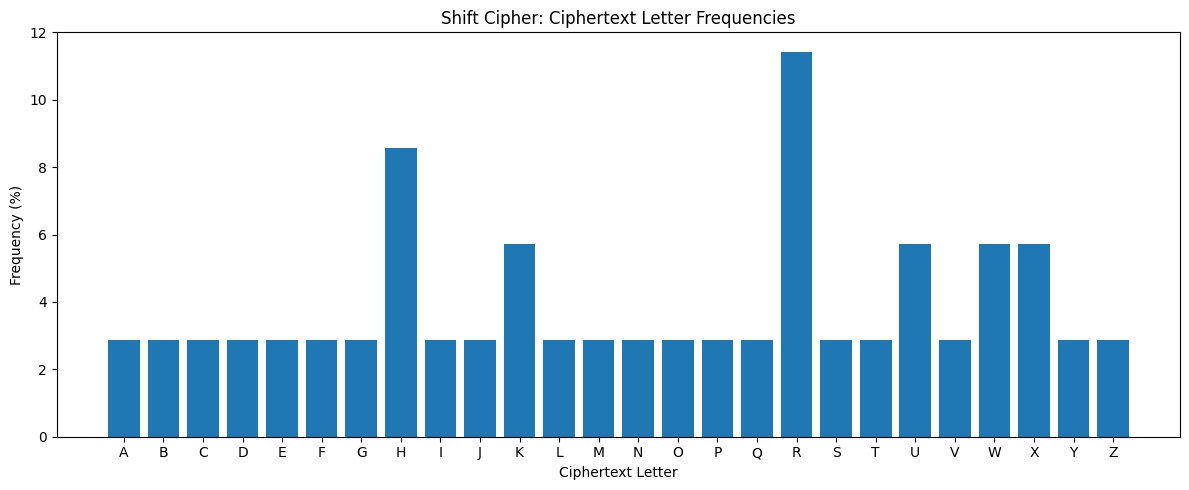

In [20]:

import matplotlib.pyplot as plt

letters = list(frequencies.keys())
percentages = list(frequencies.values())

plt.figure(figsize=(12, 5))
plt.bar(letters, percentages)
plt.xlabel("Ciphertext Letter")
plt.ylabel("Frequency (%)")
plt.title("Shift Cipher: Ciphertext Letter Frequencies")
plt.tight_layout()
plt.show()


## 9. Ranking Candidate Plaintexts

Brute-force search generates all possible decryptions but does not automatically identify the correct message. We can improve the process by scoring each candidate according to how closely its letter frequencies resemble typical English.

For this demonstration, we use a simple chi-squared statistic:

\[
\chi^2=\sum_{i=1}^{26}\frac{(O_i-E_i)^2}{E_i}
\]

Here:

- \(O_i\) is the observed count of a letter in a candidate plaintext.
- \(E_i\) is the expected count for that letter based on typical English frequencies.

Lower scores indicate a closer match to the reference frequency distribution.

This method is a heuristic. It may rank the wrong candidate first when messages are short, contain unusual vocabulary, or are not written in English.

In [21]:

from collections import Counter

ENGLISH_FREQUENCIES = {
    "A": 8.167, "B": 1.492, "C": 2.782, "D": 4.253,
    "E": 12.702, "F": 2.228, "G": 2.015, "H": 6.094,
    "I": 6.966, "J": 0.153, "K": 0.772, "L": 4.025,
    "M": 2.406, "N": 6.749, "O": 7.507, "P": 1.929,
    "Q": 0.095, "R": 5.987, "S": 6.327, "T": 9.056,
    "U": 2.758, "V": 0.978, "W": 2.360, "X": 0.150,
    "Y": 1.974, "Z": 0.074
}


def english_score(text):
    letters = [
        char.upper()
        for char in text
        if char.isascii() and char.isalpha()
    ]

    if not letters:
        return float("inf")

    counts = Counter(letters)
    total = len(letters)
    score = 0

    for letter, percentage in ENGLISH_FREQUENCIES.items():
        observed = counts.get(letter, 0)
        expected = total * percentage / 100
        score += (observed - expected) ** 2 / expected

    return score


def rank_candidates(ciphertext):
    candidates = brute_force_attack(ciphertext)

    return sorted(
        candidates,
        key=lambda item: english_score(item[1])
    )


for candidate_key, candidate_text in rank_candidates(ciphertext)[:5]:
    print(
        f"Key {candidate_key:2} | "
        f"Score: {english_score(candidate_text):.2f} | "
        f"{candidate_text}"
    )


Key  7 | Score: 19.82 | Meet me at the library
Key  0 | Score: 35.35 | Tlla tl ha aol spiyhyf
Key  4 | Score: 56.05 | Phhw ph dw wkh oleudub
Key 23 | Score: 68.36 | Wood wo kd dro vslbkbi
Key 13 | Score: 73.82 | Gyyn gy un nby fcvluls


## 10. Security Analysis

The Shift Cipher is useful for learning substitution and modular arithmetic, but it is fundamentally insecure for modern communication.

### Major weaknesses

**1. Small keyspace**

There are only 26 distinct shifts, including the identity shift of zero. An attacker can exhaustively test every possible key.

**2. Frequency preservation**

Every plaintext letter is consistently replaced by the same ciphertext letter. The statistical patterns of the original language remain present in the ciphertext.

**3. Vulnerability to known-plaintext attacks**

A single corresponding plaintext-ciphertext letter pair reveals the key, assuming the standard Shift Cipher model.

**4. No integrity protection**

The cipher does not detect whether a message has been modified. An attacker can change ciphertext letters and potentially cause predictable changes in the decrypted message.

**5. No authentication**

The cipher does not establish the sender's identity or prove that a message came from a trusted party.

### Appropriate use

The Shift Cipher is suitable for educational demonstrations, introductory cryptography exercises, and illustrating basic cryptanalysis. It should not be used to protect passwords, personal information, financial data, or communications.

Modern secure communication requires appropriately designed cryptographic protocols and established cryptographic libraries rather than classical substitution ciphers.

## 11. Complexity Analysis

Let \(n\) represent the number of characters in the input message.

| Operation | Time complexity | Auxiliary space |
|---|---|---|
| Encryption | \(O(n)\) | \(O(n)\) for the result |
| Decryption | \(O(n)\) | \(O(n)\) for the result |
| Brute-force attack | \(O(26n)=O(n)\) | \(O(26n)=O(n)\) for all candidates |
| Known-plaintext key recovery | \(O(1)\) for the first letter pair | \(O(1)\) |
| Frequency calculation | \(O(n)\) | \(O(1)\) for the fixed 26-letter frequency table |
| Candidate ranking | \(O(26n)=O(n)\) for a fixed alphabet | \(O(n)\) when candidates are stored |

The encryption and decryption functions create new strings, so their output requires space proportional to the input length.

The brute-force attack processes the ciphertext once for each possible key. Since the number of keys is fixed at 26, its asymptotic time complexity is linear in the message length.

The known-plaintext implementation returns the key using the first letter pair, making the key calculation constant-time. This assumes the input has already passed validation.

These complexities describe the implementations in this notebook and assume ordinary Python operations on characters and strings.

## 12. Conclusion

This project implements the Shift Cipher from scratch and demonstrates its behavior through encryption, decryption, automated tests, brute-force cryptanalysis, known-plaintext key recovery, and frequency analysis.

The implementation illustrates how modular arithmetic can transform text and how input validation and testing improve software reliability.

The cryptanalysis experiments demonstrate that a cipher can correctly encrypt and decrypt messages while still providing very little security. A small keyspace makes exhaustive search feasible, and the preservation of language statistics creates additional weaknesses.

The project establishes a foundation for studying more advanced classical ciphers, including substitution, transposition, Vigenère, and Playfair ciphers, before progressing to modern symmetric and public-key cryptography.

**Key takeaway:** Correct implementation is not the same as strong security. Cryptographic security depends on the algorithm's design, keyspace, threat model, and resistance to known attacks.